In [1]:
import sys
print(sys.version)
print(sys.executable)

3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:23:37) [Clang 14.0.6 ]
/opt/miniconda3/bin/python


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules

# Load Dataset

In [3]:
df = pd.read_csv('Online Retail.csv',sep=";", decimal=",")
print('Shape:', df.shape)
df.head()


Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/10 08.26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/10 08.26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/10 08.26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/10 08.26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/10 08.26,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [5]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


# Eksplorasi dan Pembersihan Data

In [6]:
missing = pd.DataFrame({
    'count' : df.isna().sum(),
    'percentage' : (df.isna().mean()*100).round(1),

}).sort_values('count',ascending=False)
missing[missing['count']>0]

,count,percentage
CustomerID,135080,24.9
Description,1454,0.3


In [7]:
# Kolom yang relevan untuk association rule: InvoiceNo (transaksi) dan Description (produk)
print('Jumlah invoice unik:', df['InvoiceNo'].nunique())
print('Jumlah produk unik:', df['Description'].nunique())
print('Baris transaksi batal (InvoiceNo diawali C):', df['InvoiceNo'].astype(str).str.startswith('C').sum())
print('Baris dengan Quantity <= 0:', (df['Quantity'] <= 0).sum())

Jumlah invoice unik: 25900
Jumlah produk unik: 4223
Baris transaksi batal (InvoiceNo diawali C): 9288
Baris dengan Quantity <= 0: 10624


In [8]:
# Pembersihan data, jumlah baris dan invoice dicatat di setiap langkah
tahap = {'Awal': df}

df_clean = df.dropna(subset=['Description'])
tahap['Hapus Description kosong'] = df_clean

df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
tahap['Hapus transaksi batal (C)'] = df_clean

df_clean = df_clean[df_clean['Quantity'] > 0].copy()
tahap['Hapus Quantity <= 0'] = df_clean

# Rapikan spasi di Description, lalu hapus baris yang bukan produk (ongkos kirim dan input manual)
df_clean['Description'] = df_clean['Description'].str.strip()
non_produk = ['POSTAGE', 'DOTCOM POSTAGE', 'CARRIAGE', 'Manual']
df_clean = df_clean[~df_clean['Description'].isin(non_produk)]
tahap['Hapus item non-produk'] = df_clean

ringkasan = pd.DataFrame({nama: {'Baris': len(d), 'Invoice': d['InvoiceNo'].nunique()} for nama, d in tahap.items()}).T
ringkasan

,Baris,Invoice
Awal,541909,25900
Hapus Description kosong,540455,24446
Hapus transaksi batal (C),531167,20610
Hapus Quantity <= 0,530693,20136
Hapus item non-produk,528390,19973


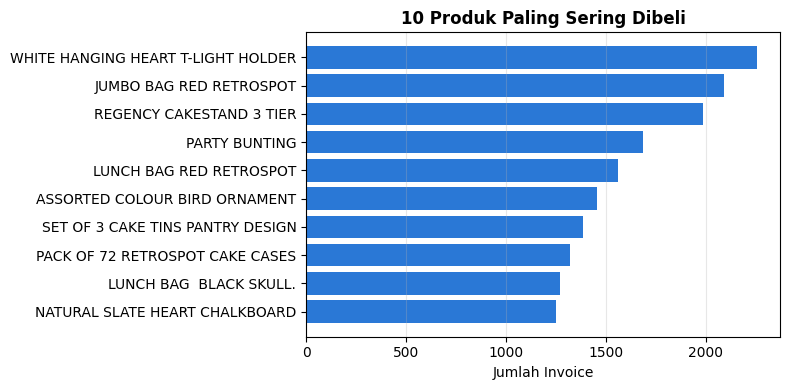

In [9]:
# 10 produk yang paling sering dibeli (dihitung dari jumlah invoice yang memuat produk tsb)
top_produk = df_clean.groupby('Description')['InvoiceNo'].nunique().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top_produk.index[::-1], top_produk.values[::-1], color='#2a78d6')
ax.set_xlabel('Jumlah Invoice')
ax.set_title('10 Produk Paling Sering Dibeli', fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# Persiapan Data untuk Association Rule

In [10]:
# Satu transaksi = satu invoice, isinya daftar produk yang dibeli
transaksi = df_clean.groupby('InvoiceNo')['Description'].apply(list)
print('Jumlah transaksi:', len(transaksi))
print('Rata-rata produk per transaksi: %.1f' % transaksi.apply(len).mean())
transaksi.head()

Jumlah transaksi: 19973
Rata-rata produk per transaksi: 26.5


InvoiceNo
536365    [WHITE HANGING HEART T-LIGHT HOLDER, WHITE MET...
536366    [HAND WARMER UNION JACK, HAND WARMER RED POLKA...
536367    [ASSORTED COLOUR BIRD ORNAMENT, POPPY'S PLAYHO...
536368    [JAM MAKING SET WITH JARS, RED COAT RACK PARIS...
536369                           [BATH BUILDING BLOCK WORD]
Name: Description, dtype: object

In [11]:
# Ubah ke bentuk one-hot (basket): baris = invoice, kolom = produk, True kalau produk dibeli
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
basket = pd.DataFrame(te.fit_transform(transaksi), columns=te.columns_)
print('Ukuran basket:', basket.shape)
basket.head()

Ukuran basket: (19973, 4061)


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,returned,taig adjust,test,to push order througha s stock was,website fixed,wrongly coded 20713,wrongly coded 23343,wrongly marked,wrongly marked 23343,wrongly sold (22719) barcode
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


# Association Rules (Apriori)

In [12]:
# Titik awal: min_support 0.01 dan min_confidence 0.5
itemsets_awal = apriori(basket, min_support=0.01, use_colnames=True)
rules_awal = association_rules(itemsets_awal, metric='confidence', min_threshold=0.5)
print('Jumlah frequent itemset:', len(itemsets_awal))
print('Jumlah aturan:', len(rules_awal))
rules_awal.sort_values('lift', ascending=False)[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10)

Jumlah frequent itemset: 1820
Jumlah aturan: 816


,antecedents,consequents,support,confidence,lift
360,(HERB MARKER THYME),"(HERB MARKER PARSLEY, HERB MARKER ROSEMARY)",0.010164,0.856540,79.570582
357,"(HERB MARKER PARSLEY, HERB MARKER ROSEMARY)",(HERB MARKER THYME),0.010164,0.944186,79.570582
361,(HERB MARKER ROSEMARY),"(HERB MARKER PARSLEY, HERB MARKER THYME)",0.010164,0.845833,79.313752
356,"(HERB MARKER PARSLEY, HERB MARKER THYME)",(HERB MARKER ROSEMARY),0.010164,0.953052,79.313752
355,(HERB MARKER ROSEMARY),"(HERB MARKER BASIL, HERB MARKER THYME)",0.010014,0.833333,79.257937
350,"(HERB MARKER BASIL, HERB MARKER THYME)",(HERB MARKER ROSEMARY),0.010014,0.952381,79.257937
352,"(HERB MARKER BASIL, HERB MARKER ROSEMARY)",(HERB MARKER THYME),0.010014,0.934579,78.760992
353,(HERB MARKER THYME),"(HERB MARKER BASIL, HERB MARKER ROSEMARY)",0.010014,0.843882,78.760992
111,(HERB MARKER ROSEMARY),(HERB MARKER THYME),0.011065,0.920833,77.602549
110,(HERB MARKER THYME),(HERB MARKER ROSEMARY),0.011065,0.932489,77.602549


In [13]:
# Jumlah aturan untuk beberapa kombinasi min_support dan min_confidence
jumlah = []
for sup in [0.01, 0.015, 0.02, 0.03]:
    for conf in [0.5, 0.6, 0.7]:
        r = association_rules(itemsets_awal[itemsets_awal['support'] >= sup], metric='confidence', min_threshold=conf)
        jumlah.append({'min_support': sup, 'min_confidence': conf, 'jumlah_aturan': len(r)})
pd.DataFrame(jumlah).pivot(index='min_support', columns='min_confidence', values='jumlah_aturan')

min_confidence,0.5,0.6,0.7
min_support,,,
0.010,816,484,261
0.015,182,97,45
0.020,60,30,13
0.030,11,8,3


**Penyesuaian min_support dan min_confidence**

Dengan titik awal min_support 0.01 dan min_confidence 0.5 dihasilkan 816 aturan. Jumlah ini terlalu banyak untuk dianalisis, dan sebagian besar kurang berguna:
- 634 dari 816 aturan (78%) support-nya di bawah 0.015, jadi hanya pas-pasan di atas batas (sekitar 200 sampai 300 invoice dari 19.973).
- 10 aturan dengan lift tertinggi (tabel di atas) semuanya dari satu keluarga produk, HERB MARKER, hanya beda kombinasi dan arah.

Karena itu min_support dinaikkan ke **0.015** (produk minimal muncul bersama di sekitar 300 invoice) dan min_confidence ke **0.6** (produk di sisi kanan dibeli di minimal 60% transaksi yang memuat sisi kiri). Hasilnya 97 aturan: masih cukup banyak untuk dianalisis dan produknya lebih beragam. Menaikkan ke 0.02 ke atas justru membuang pasangan produk yang jelas berkaitan (misalnya REGENCY TEA PLATE dan POPPY'S PLAYHOUSE dengan support sekitar 0.016), dan 0.03 hanya menyisakan 3 sampai 11 aturan.

In [14]:
# Nilai yang dipakai: min_support 0.015 dan min_confidence 0.6
frequent_itemsets = apriori(basket, min_support=0.015, use_colnames=True)
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.6)
print('Jumlah frequent itemset:', len(frequent_itemsets))
print('Jumlah aturan:', len(rules))

Jumlah frequent itemset: 701
Jumlah aturan: 97


# Evaluasi Aturan Asosiasi

In [15]:
# Semua aturan beserta support, confidence, dan lift (urut dari lift tertinggi)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', None)
rules = rules.sort_values(['lift', 'confidence'], ascending=False).reset_index(drop=True)
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].round(3)

,antecedents,consequents,support,confidence,lift
0,(REGENCY TEA PLATE GREEN),(REGENCY TEA PLATE ROSES),0.016,0.837,37.579
1,(REGENCY TEA PLATE ROSES),(REGENCY TEA PLATE GREEN),0.016,0.717,37.579
2,(POPPY'S PLAYHOUSE BEDROOM),(POPPY'S PLAYHOUSE KITCHEN),0.016,0.740,33.897
3,(POPPY'S PLAYHOUSE KITCHEN),(POPPY'S PLAYHOUSE BEDROOM),0.016,0.718,33.897
4,(SET/6 RED SPOTTY PAPER CUPS),(SET/6 RED SPOTTY PAPER PLATES),0.018,0.818,30.993
5,(SET/6 RED SPOTTY PAPER PLATES),(SET/6 RED SPOTTY PAPER CUPS),0.018,0.664,30.993
6,(SMALL MARSHMALLOWS PINK BOWL),(SMALL DOLLY MIX DESIGN ORANGE BOWL),0.017,0.781,29.590
7,(SMALL DOLLY MIX DESIGN ORANGE BOWL),(SMALL MARSHMALLOWS PINK BOWL),0.017,0.662,29.590
8,(WOODEN STAR CHRISTMAS SCANDINAVIAN),(WOODEN HEART CHRISTMAS SCANDINAVIAN),0.019,0.758,28.133
9,(WOODEN HEART CHRISTMAS SCANDINAVIAN),(WOODEN STAR CHRISTMAS SCANDINAVIAN),0.019,0.721,28.133


In [16]:
# Ringkasan metrik dari semua aturan
rules[['support', 'confidence', 'lift']].describe().round(3)

,support,confidence,lift
count,97.000,97.000,97.000
mean,0.020,0.707,15.161
std,0.006,0.078,7.191
min,0.015,0.600,5.838
25%,0.016,0.646,10.199
50%,0.017,0.679,15.019
75%,0.022,0.757,17.464
max,0.041,0.909,37.579


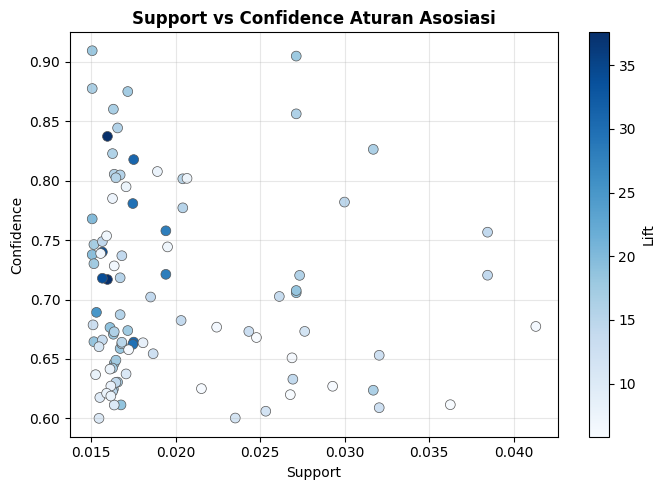

In [17]:
# Sebaran aturan: support vs confidence, warna = lift
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(rules['support'], rules['confidence'], c=rules['lift'], cmap='Blues', s=50, edgecolors='#555555', linewidths=0.5)
plt.colorbar(sc, label='Lift')
ax.set_xlabel('Support')
ax.set_ylabel('Confidence')
ax.set_title('Support vs Confidence Aturan Asosiasi', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Tiga aturan terbaik berdasarkan lift
# A -> B dan B -> A punya lift yang sama, jadi dari satu kombinasi produk diambil satu arah saja (confidence tertinggi)
rules['itemset'] = [a | c for a, c in zip(rules['antecedents'], rules['consequents'])]
top3 = (rules.sort_values('confidence', ascending=False)
             .drop_duplicates('itemset')
             .sort_values('lift', ascending=False)
             .head(3))
top3[['antecedents', 'consequents', 'antecedent support', 'consequent support', 'support', 'confidence', 'lift']].round(3)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,(REGENCY TEA PLATE GREEN),(REGENCY TEA PLATE ROSES),0.019,0.022,0.016,0.837,37.579
2,(POPPY'S PLAYHOUSE BEDROOM),(POPPY'S PLAYHOUSE KITCHEN),0.021,0.022,0.016,0.740,33.897
4,(SET/6 RED SPOTTY PAPER CUPS),(SET/6 RED SPOTTY PAPER PLATES),0.021,0.026,0.018,0.818,30.993


**Interpretasi tiga aturan terbaik (lift tertinggi)**

1. **REGENCY TEA PLATE GREEN → REGENCY TEA PLATE ROSES** (support 0.016, confidence 0.837, lift 37.6)
   Dari 381 invoice yang membeli piring teh REGENCY hijau, 319 (84%) juga membeli motif mawar. Peluang ini 37.6 kali lebih besar dibanding pelanggan pada umumnya (2.2%). Pelanggan membeli piring REGENCY sebagai satu set beda motif, jadi toko bisa menjualnya sebagai paket set, menampilkannya berdampingan, dan menjaga stok semua motif tersedia bersamaan.

2. **POPPY'S PLAYHOUSE BEDROOM → POPPY'S PLAYHOUSE KITCHEN** (support 0.016, confidence 0.740, lift 33.9)
   74% pembeli rumah-rumahan bagian kamar tidur juga membeli bagian dapur. Produk ini satu seri mainan yang dikoleksi per ruangan, jadi cocok untuk rekomendasi "lengkapi koleksi" di halaman produk atau bundling beberapa ruangan dengan potongan harga.

3. **SET/6 RED SPOTTY PAPER CUPS → SET/6 RED SPOTTY PAPER PLATES** (support 0.018, confidence 0.818, lift 31.0)
   82% pembeli gelas kertas polkadot merah juga membeli piring kertas dengan motif yang sama. Keduanya perlengkapan pesta yang dipakai bersamaan, jadi bisa dijual sebagai paket pesta, dan pembeli gelas langsung disarankan piringnya (cross-selling).

Ketiga aturan berasal dari produk satu seri atau satu desain. Lift-nya sangat tinggi (di atas 30), tapi support-nya kecil (sekitar 1.6 sampai 1.8% transaksi), jadi aturan ini paling berguna untuk rekomendasi produk dan paket set.